In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
import sys
import yaml
from pathlib import Path
from tqdm.auto import tqdm
from joblib import Parallel, delayed
from scipy.spatial.distance import hamming

# make figures paper quality
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# matplotlib.rcParams['font.family'] = 'Arial'

import warnings
warnings.filterwarnings("ignore")

/home/peidli/miniconda3/envs/sc_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']
path = Path(config['TEMPDIR']) / 'pooled_screen_1/'
# path = Path("/Users/peidli/work/data/SYMPHONY/pooled_screen_1/")

# Bagel2

## Data selections

In [7]:
df = pd.read_csv(path / 'pooled_screen_1_counts.csv')

In [8]:
line = 'H1975'

In [9]:
sdf = df.copy()

In [32]:
mask = [(cell_line_dict[int(x.split('-')[1])]==line) if 'sym' in x else True if 'pool' in x else False for x in sdf.columns]

In [33]:
df.loc[:, mask]

,Sym-pool-1-1,Sym-pool-1-2,Sym-pool-1-3,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,sym-01-01-TP6,sym-01-02-TP1,...,sym-01-02-TP3,sym-01-02-TP4,sym-01-02-TP5,sym-01-02-TP6,sym-01-03-TP1,sym-01-03-TP2,sym-01-03-TP3,sym-01-03-TP4,sym-01-03-TP5,sym-01-03-TP6
0,2361,2599,3522,3348,3068,2844,3879,2833,2405,3210,...,2478,2366,1967,3290,3200,2742,2702,2464,2371,2351
1,3330,3607,4864,4715,4947,4048,5521,3671,3562,4141,...,3107,3463,3027,4228,4088,3871,4111,3994,4408,4218
2,2138,2139,3108,3101,3107,2701,3749,2196,3012,2762,...,2613,2794,2348,2869,2774,2745,3370,2668,3222,2930
3,1994,2038,2838,2358,2162,1771,2318,1499,2514,2201,...,1928,2133,2052,2026,1724,1712,1808,1973,1595,1604
4,3321,3027,4610,3655,4296,3384,4973,3267,4197,3728,...,3725,3895,3746,3811,4403,4300,4440,3707,4020,4010
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6220,2782,2747,3925,2180,457,107,47,0,0,1035,...,59,21,2,0,1079,347,80,20,65,56
6221,2046,2117,2834,3516,2088,1163,1157,591,435,1900,...,729,604,494,586,2005,1355,823,705,550,457
6222,2713,2873,3947,3477,2315,1481,1701,921,801,2497,...,1139,1121,771,826,2799,2524,1899,1416,1256,1094
6223,1846,1912,2651,2614,1972,1575,1752,1167,1414,1789,...,1536,1580,1154,1000,1783,1833,1441,1082,902,939


In [44]:
sdf = pd.read_csv('/scratch/peidli/SYMPHONY/pooled_screen_1/bagel2/pooled_screen_1_bagel_gene_TP5TP6_A549.foldchange', sep='\t')

In [45]:
sdf

,REAGENT_ID,GENE,sym-03-01-TP5,sym-03-01-TP6,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP5,sym-03-03-TP6
0,AATBC_ENST00000400385_1005,AATBC,0.289,0.257,0.389,0.246,0.307,0.284
1,AATBC_ENST00000400385_1562,AATBC,0.411,0.372,0.297,0.402,0.374,0.446
2,AATBC_ENST00000400385_1938,AATBC,0.281,0.318,0.351,0.426,0.342,0.484
3,AATBC_ENST00000400385_2713,AATBC,-0.079,0.151,0.068,0.010,0.001,0.215
4,AATBC_ENST00000400385_28,AATBC,0.206,0.220,0.139,0.279,0.240,0.319
...,...,...,...,...,...,...,...,...
6220,RPS16_ENST00000251453_280,RPS16,-2.589,-3.074,-2.335,-3.000,-2.843,-3.006
6221,RPS16_ENST00000251453_300,RPS16,-3.271,-3.640,-2.726,-3.095,-3.201,-3.271
6222,RPS5_ENST00000196551_431,RPS5,-1.045,-1.600,-0.893,-1.112,-1.279,-1.415
6223,RPS5_ENST00000196551_574,RPS5,-0.641,-0.443,-0.490,-0.647,-0.461,-0.516


## Transcript (disfunct)

In [36]:
input_transcript =pd.read_table('/scratch/peidli/SYMPHONY/pooled_screen_1/bagel2/pooled_screen_1_bagel2_input_transcript.txt')
input_gene =pd.read_table('/scratch/peidli/SYMPHONY/pooled_screen_1/bagel2/pooled_screen_1_bagel2_input_gene.txt')

In [37]:
input_transcript

,sgRNA,Transcript_ID,Sym-pool-1-1,Sym-pool-1-2,Sym-pool-1-3,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,...,sym-03-02-TP2,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
0,AATBC_ENST00000400385_1005,ENST00000400385,2361,2599,3522,3348,3068,2844,3879,2833,...,1235,1494,1747,1655,1494,1545,1298,1842,1277,1391
1,AATBC_ENST00000400385_1562,ENST00000400385,3330,3607,4864,4715,4947,4049,5521,3671,...,1885,2072,2450,2161,2318,2164,1775,2276,1863,2168
2,AATBC_ENST00000400385_1938,ENST00000400385,2138,2139,3108,3102,3107,2701,3749,2196,...,1199,1299,1680,1402,1473,1463,1166,1650,1139,1391
3,AATBC_ENST00000400385_2713,ENST00000400385,1995,2038,2838,2358,2162,1771,2318,1499,...,799,1175,1268,1071,1026,1157,892,1263,835,1073
4,AATBC_ENST00000400385_28,ENST00000400385,3321,3027,4610,3655,4296,3384,4974,3267,...,1518,1898,2201,1797,1975,2039,1678,2248,1576,1842
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6120,RPS16_ENST00000251453_280,ENST00000251453,2782,2747,3925,2180,457,107,47,0,...,442,337,335,275,171,1198,468,230,156,154
6121,RPS16_ENST00000251453_300,ENST00000251453,2046,2117,2834,3516,2088,1164,1157,592,...,227,187,155,153,117,901,319,106,88,93
6122,RPS5_ENST00000196551_431,ENST00000196551,2713,2873,3947,3477,2315,1481,1701,921,...,821,865,787,762,653,1532,864,669,475,478
6123,RPS5_ENST00000196551_574,ENST00000196551,1846,1912,2651,2614,1972,1575,1752,1167,...,636,750,835,677,605,989,659,869,564,601


In [40]:
input_transcript.Transcript_ID.value_counts()

Transcript_ID
ENST00000400385    10
ENST00000483525    10
ENST00000414938    10
ENST00000440444    10
ENST00000598996    10
                   ..
ENST00000495032     2
ENST00000368783     2
ENST00000318059     2
ENST00000334371     2
ENST00000512737     2
Name: count, Length: 844, dtype: int64

In [39]:
input_gene.Gene.value_counts()

Gene
NT_Control    100
HOTAIRM1       42
LINC-PINT      28
BIN1           28
RAN            21
             ... 
KRTAP5-7        3
PAM16           2
NME2            2
LCE2C           2
LCE1F           2
Name: count, Length: 734, dtype: int64

In [33]:
input_transcript.value_counts('Transcript_ID')

Transcript_ID
ENST00000520395    10
ENST00000400946    10
ENST00000502066    10
ENST00000501122    10
ENST00000499203    10
                   ..
ENST00000368783     2
ENST00000334371     2
ENST00000512737     2
ENST00000495032     2
ENST00000318059     2
Name: count, Length: 844, dtype: int64

In [21]:
# 100 transcripts are unique
(input_transcript.value_counts('Transcript_ID')==1).sum()

100

In [19]:
pr_data = pd.read_table('../results/tables/pooled_screen_1_bagel_pr_transcript.tsv', index_col=0)
pr_data.info()

FileNotFoundError: [Errno 2] No such file or directory: '../results/tables/pooled_screen_1_bagel_pr_transcript.tsv'

In [ ]:
pl.figure(figsize=(4,4))
pl.plot( pr_data.Recall, pr_data.Precision, linewidth=2)
pl.xlim(0,1.01)
pl.ylim(0,1.02)
pl.xlabel('Recall')
pl.ylabel('Precision (1-FDR)')
pl.title('BAGEL2 Transcript-wise Precision-Recall Plot')
pl.show()

In [ ]:
# ideal distribution of Bayes Factors:
# BF>3 to 5 are minimum-confidence essentials; >10 are high-confidence.
pl.figure(figsize=(4,4))
pr_data.hist('BF', bins=100)
pl.axvline(10, color='r', linestyle='--', label='BF=10')
pl.xlabel('Bayes Factor')
pl.ylabel('Number of Transcripts')
pl.legend()
pl.show()

## Gene

In [10]:
file = '../results/tables/pooled_screen_1_bagel_pr_gene.tsv'

if Path(file).exists():
    df = pd.read_table(file, index_col=0, header=[0,1,2])
else:
    # aggregate results
    datas = {}
    for line in ['alllines', 'A549', 'H1299', 'H1975']:
        for time in ['alltimes', 'TP5TP6']:
            tdf = pd.read_table(f'../results/tables/pooled_screen_1_bagel_pr_gene_{time}_{line}.tsv', index_col='Gene')
            datas[(line, time)] = tdf
    df = pd.concat(datas, axis=1)

    # write to file
    df.to_csv(file, sep='\t')

In [19]:
# Annotate essentiallity based on original Bagel list
essential = pd.read_csv("/home/peidli/utils/bagel/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("/home/peidli/utils/bagel/NEGv1.txt", sep='\t', index_col=0)
df['essentiality'] = ['essential' if g in essential.index else 'non-essential' if g in non_essential.index else 'unknown' for g in df.index]

In [24]:
df

alllines                                                     \
            alltimes                            TP5TP6                    
                  BF Recall Precision    FDR        BF Recall Precision   
Gene                                                                      
RAN         9969.672  0.005     1.000  0.000  5798.778  0.005     1.000   
FBL         5449.419  0.005     1.000  0.000  3394.553  0.005     1.000   
EIF4A1      4661.117  0.005     1.000  0.000  2410.584  0.010     1.000   
HNRNPA1     4135.492  0.005     1.000  0.000  2185.951  0.010     1.000   
SNHG16      3811.712  0.005     1.000  0.000  2233.446  0.010     1.000   
...              ...    ...       ...    ...       ...    ...       ...   
PCAT1      -1172.589  1.000     0.865  0.135  -553.261  1.000     0.865   
PCBP4      -1203.189  1.000     0.865  0.135  -600.722  1.000     0.865   
BIN1       -1436.490  1.000     0.865  0.135  -639.859  1.000     0.865   
HOTAIRM1   -1581.295  1.000     0.865  0.135  -800.927  1.000     0.865   
NT_Control -2505.494  1.000     0.865  0.135 -1424.679  1.000     0.865   

                       A549         ...    H1975                             \
                   alltimes         ... alltimes                     TP5TP6   
              FDR        BF Recall  ...   Recall Precision    FDR        BF   
Gene                                ...                                       
RAN         0.000  2046.360  0.005  ...    0.005     1.000  0.000  1322.864   
FBL         0.000   586.054  0.065  ...    0.005     1.000  0.000  1260.358   
EIF4A1      0.000  1225.385  0.005  ...    0.005     1.000  0.000   564.761   
HNRNPA1     0.000  1146.395  0.005  ...    0.020     1.000  0.000   428.998   
SNHG16      0.000  1001.866  0.015  ...    0.020     1.000  0.000   471.557   
...           ...       ...    ...  ...      ...       ...    ...       ...   
PCAT1       0.135  -340.449  1.000  ...    1.000     0.865  0.135  -186.700   
PCBP4       0.135  -368.308  1.000  ...    1.000     0.865  0.135  -206.198   
BIN1        0.135  -344.503  1.000  ...    1.000     0.865  0.135  -276.360   
HOTAIRM1    0.135  -474.106  1.000  ...    1.000     0.865  0.135  -248.370   
NT_Control  0.135  -516.507  1.000  ...    1.000     0.865  0.135  -542.439   

                                     bla is_essential essentiality  
                                                                    
           Recall Precision    FDR                                  
Gene                                                                
RAN         0.005     1.000  0.000  helo         True    essential  
FBL         0.005     1.000  0.000  helo        False      unknown  
EIF4A1      0.005     1.000  0.000  helo        False      unknown  
HNRNPA1     0.015     1.000  0.000  helo        False      unknown  
SNHG16      0.015     1.000  0.000  helo        False      unknown  
...           ...       ...    ...   ...          ...          ...  
PCAT1       1.000     0.865  0.135  helo        False      unknown  
PCBP4       1.000     0.865  0.135  helo        False      unknown  
BIN1        1.000     0.865  0.135  helo        False      unknown  
HOTAIRM1    1.000     0.865  0.135  helo        False      unknown  
NT_Control  1.000     0.865  0.135  helo        False      unknown  

[734 rows x 35 columns]

In [49]:
sdf = df.loc[:, ('alllines', 'alltimes', slice(None, None, None))]  # get all entries
# now remove the multi-index
sdf.columns = sdf.columns.droplevel([0,1])
sdf['essentiality'] = df['essentiality']

In [50]:
sdf

,BF,Recall,Precision,FDR,essentiality
Gene,,,,,
RAN,9969.672,0.005,1.000,0.000,essential
FBL,5449.419,0.005,1.000,0.000,unknown
EIF4A1,4661.117,0.005,1.000,0.000,unknown
HNRNPA1,4135.492,0.005,1.000,0.000,unknown
SNHG16,3811.712,0.005,1.000,0.000,unknown
...,...,...,...,...,...
PCAT1,-1172.589,1.000,0.865,0.135,unknown
PCBP4,-1203.189,1.000,0.865,0.135,unknown
BIN1,-1436.490,1.000,0.865,0.135,unknown


In [51]:
# sdf has these columns: 'BF', 'Recall', 'Precision', 'FDR', 'essentiality'

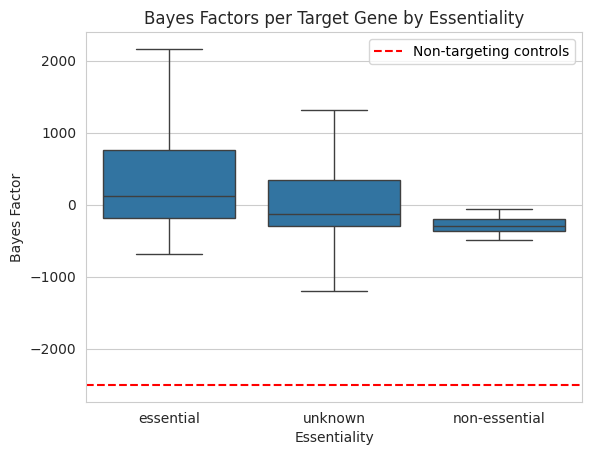

In [68]:
with sns.axes_style('whitegrid'):
    sns.boxplot(data=sdf, x='essentiality', y='BF', showfliers=False)
pl.axhline(sdf.loc['NT_Control', 'BF'], color='r', linestyle='--', label='Non-targeting controls')
pl.legend()
pl.ylabel('Bayes Factor')
pl.xlabel('Essentiality')
pl.title('Bayes Factors per Target Gene by Essentiality')
pl.show()

In [69]:
# BF vs guide score
cts = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
# df = pd.read_csv('/Users/peidli/work/data/SYMPHONY/pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(cts.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in cts.index if 'control' in x.lower()]

In [70]:
cts

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,1494,1747,1655,1494,1545,1298,1388,1842,1277,1391
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,2072,2450,2161,2318,2164,1774,2055,2276,1863,2168
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,1299,1680,1402,1473,1463,1166,1192,1650,1139,1391
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,1175,1268,1071,1026,1157,892,976,1263,835,1073
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,1898,2201,1797,1975,2039,1678,1794,2248,1576,1842
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RPS16_ENST00000251453_280,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA258:258-280,CCACCACCCTTTACACGGACACG,280.0,0.891826,CDS,631.0,...,337,335,275,171,1198,468,334,230,156,154
RPS16_ENST00000251453_300,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA278:278-300,CATAAATCTGGGCCACGTGACCA,300.0,0.892320,CDS,631.0,...,187,155,153,117,901,319,163,106,88,93
RPS5_ENST00000196551_431,ENST00000196551,ENSG00000083845,RPS5,protein_coding,crRNA409:409-431,CCACTGTTGATGATGGCGTTCAC,431.0,1.006859,CDS,741.0,...,865,787,762,652,1532,864,758,669,475,478


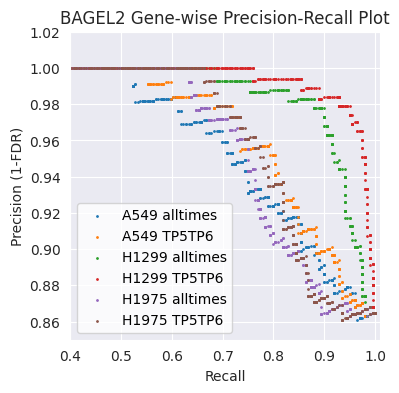

In [29]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(4,4))
selection = ['alllines', 'alltimes']
for line in ['A549', 'H1299', 'H1975']:
    for time in ['alltimes', 'TP5TP6']:
        pl.scatter(df[line, time, 'Recall'], df[line, time, 'Precision'], 
                   label=f'{line} {time}', 
                   s=1)
pl.xlim(0.4,1.01)
pl.ylim(0.85,1.02)
pl.xlabel('Recall')
pl.ylabel('Precision (1-FDR)')
pl.legend()
pl.title('BAGEL2 Gene-wise Precision-Recall Plot')
pl.show()

AttributeError: 'GrouperView' object has no attribute 'join'

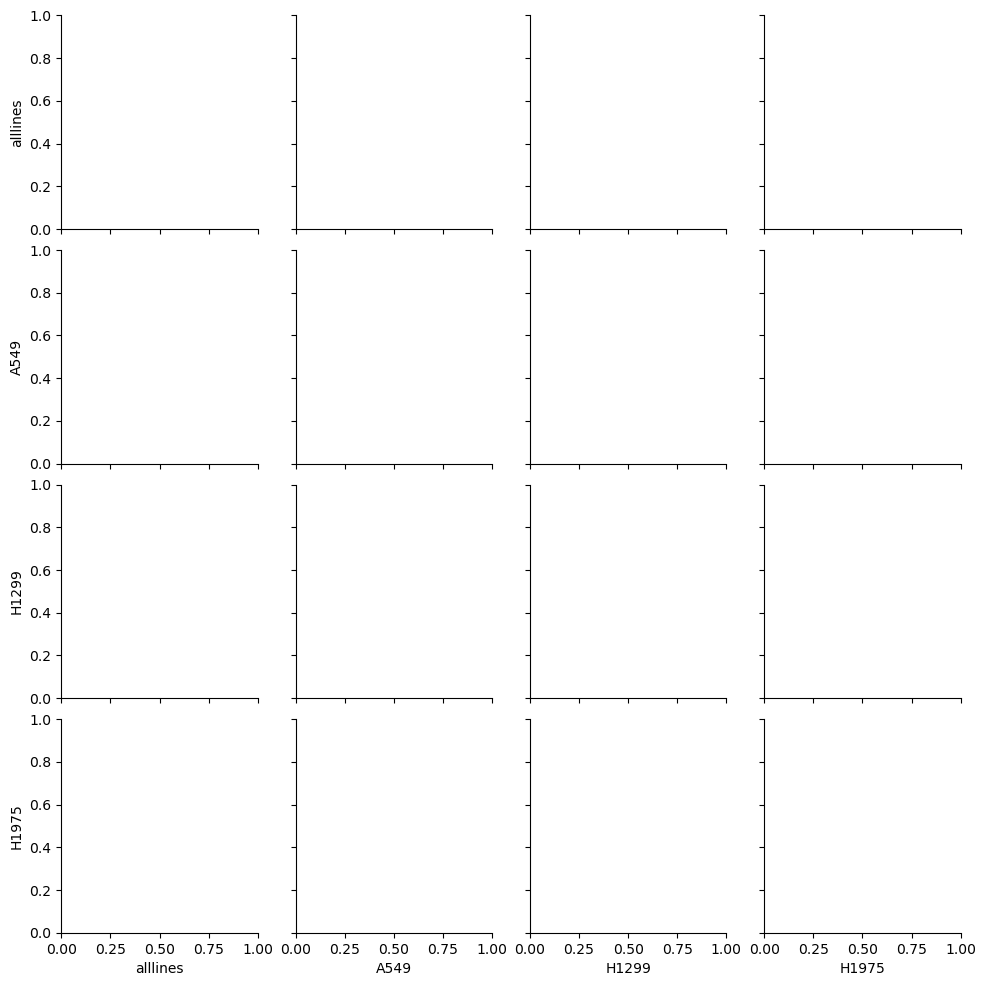

In [14]:
sdf = df.xs('BF', level=2, axis=1).xs('alltimes', level=1, axis=1)
# plot correlations between all cell lines ('alltimes', 'BF')
sns.pairplot(sdf, kind='reg', plot_kws={'line_kws':{'color':'red'}})
pl.suptitle('Pairwise correlations of Bayes Factors\nacross cell lines', y=1.04)
pl.show()

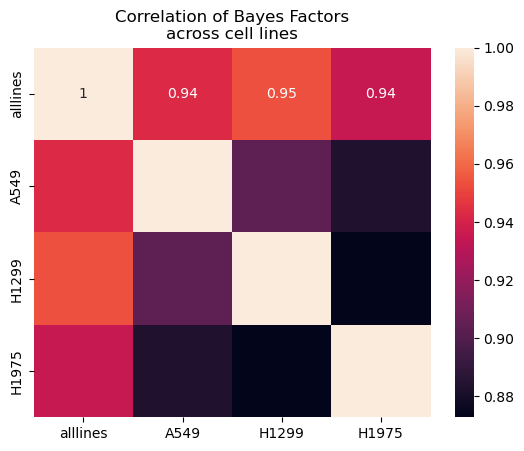

In [11]:
sdf = df.xs('BF', level=2, axis=1).xs('alltimes', level=1, axis=1)
sns.heatmap(sdf.corr(), annot=True)
pl.title('Correlation of Bayes Factors\nacross cell lines')
pl.show()

# MAGeCK

In [36]:
# The sgRNA ranking results.
guide_ranking = pd.read_csv('../results/mageck/pooled_screen_1_mageck.sgrna_summary.txt', sep='\t', index_col=0)

In [38]:
guide_ranking.head()

,Gene,control_count,treatment_count,control_mean,treat_mean,LFC,control_var,adj_var,score,p.low,p.high,p.twosided,FDR,high_in_treatment
sgrna,,,,,,,,,,,,,,
HNRNPA1_ENST00000330752_1264,HNRNPA1,100.67/117.18/55.989/67.096/79.897/45.205/742....,1920.8,100.67,1920.8,4.2404,172250.0,62197.0,7.2982,1.0,2.220400e-13,4.440800e-13,2.764400e-09,True
EEF1A1_ENST00000316292_2562,EEF1A1,204.16/63.238/112.61/117.42/59.923/87.898/682....,1545.7,117.42,1545.7,3.7072,98968.0,72542.0,5.3030,1.0,8.517900e-08,1.703600e-07,5.302400e-04,True
HIST1H2BN_ENST00000606613_239,HIST1H2BN,173.79/155/178.66/207.28/166.04/178.31/1138.7/...,1882.4,178.66,1882.4,3.3900,281540.0,110380.0,5.1281,1.0,2.076900e-07,4.153800e-07,8.619000e-04,True
RAN_ENST00000535090_322,RAN,382.45/157.48/149.72/117.42/107.36/151.94/1648...,1725.2,157.48,1725.2,3.4453,736550.0,97290.0,5.0262,1.0,3.607800e-07,7.215700e-07,9.677200e-04,True
ACTG1_ENST00000573283_1731,ACTG1,610.79/348.43/262.33/295.94/248.43/261.18/1415...,2664.0,348.43,2664.0,2.9310,422260.0,215260.0,4.9908,1.0,3.886400e-07,7.772900e-07,9.677200e-04,True


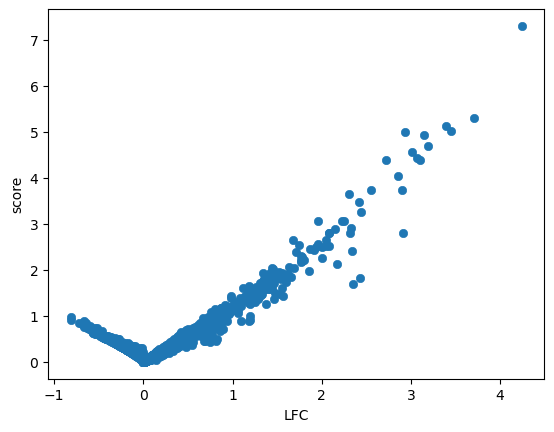

In [37]:
sns.scatterplot(data=tab, x='LFC', y='score', edgecolor=None)
pl.show()

In [40]:
# The gene ranking results.
gene_ranking = pd.read_csv('../results/mageck/pooled_screen_1_mageck.gene_summary.txt', sep='\t', index_col=0)

In [41]:
gene_ranking.head()

,num,"Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|score","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|p-value","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|fdr","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|rank","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|goodsgrna","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|lfc","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|score","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|p-value","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|fdr",...,"sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|fdr","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|rank","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|goodsgrna","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|lfc","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|score","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|p-value","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|fdr","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|rank","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|goodsgrna","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|lfc"
id,,,,,,,,,,,,,,,,,,,,,
ATP5F1D,14,4.795600e-07,0.000025,0.018116,1,6,-0.214260,0.63861,0.68762,1.0,...,0.000009,228,2,-0.027214,0.86390,0.94009,1.0,591,0,-0.027214
PCBP4,21,1.205300e-05,0.000834,0.153080,2,7,-0.233070,0.99986,1.00000,1.0,...,0.579716,718,0,-0.004687,0.45906,0.72722,1.0,321,0,-0.004687
COX8A,7,2.281700e-05,0.000271,0.068841,3,2,-0.101640,0.82811,0.92557,1.0,...,0.000009,316,1,-0.109830,0.35616,0.51852,1.0,253,0,-0.109830
NAA10,14,8.351800e-05,0.002907,0.351147,4,5,-0.155820,0.68690,0.68763,1.0,...,0.000009,278,2,-0.150320,0.67994,0.83514,1.0,475,0,-0.150320
ASB17,7,8.411100e-05,0.000281,0.068841,5,2,-0.019419,0.74969,0.89024,1.0,...,0.579716,594,0,0.055685,0.13486,0.24757,1.0,91,0,0.055685


In [49]:
df = gene_ranking.reset_index().set_index(['id', 'num'])

In [73]:
df.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in df.columns],
    [x.split('|')[1] for x in df.columns],
    [x.split('|')[2] for x in df.columns]
])

<Axes: ylabel='id-num'>

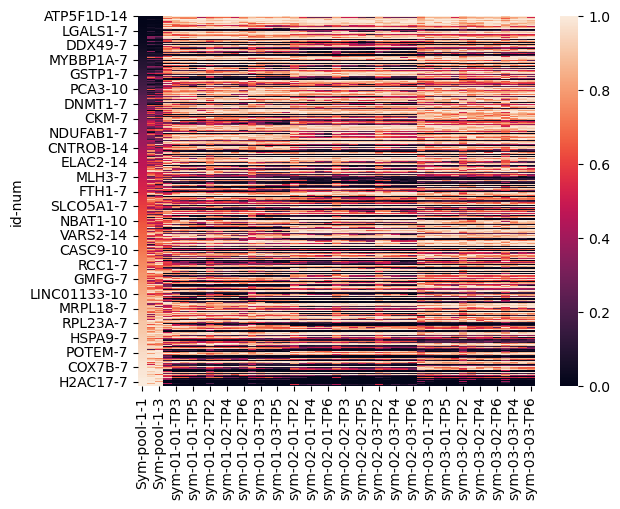

In [82]:
sns.heatmap(df.T.loc[:, 'neg', 'score'].T)

In [79]:
df.T.head(10)

id                               ATP5F1D       PCBP4       COX8A       NAA10  \
num                                   14          21          7           14   
Sym-pool-1-1 neg score      4.795600e-07    0.000012    0.000023    0.000084   
                 p-value    2.468100e-05    0.000834    0.000271    0.002907   
                 fdr        1.811600e-02    0.153080    0.068841    0.351147   
                 rank       1.000000e+00    2.000000    3.000000    4.000000   
                 goodsgrna  6.000000e+00    7.000000    2.000000    5.000000   
                 lfc       -2.142600e-01   -0.233070   -0.101640   -0.155820   
             pos score      6.386100e-01    0.999860    0.828110    0.686900   
                 p-value    6.876200e-01    1.000000    0.925570    0.687630   
                 fdr        1.000000e+00    1.000000    1.000000    1.000000   
                 rank       3.330000e+02  730.000000  500.000000  365.000000   

id                               ASB17       LSM11       PCAT1      CHCHD7  \
num                                 7           7           20          21   
Sym-pool-1-1 neg score        0.000084    0.000248    0.000759    0.000844   
                 p-value      0.000281    0.002611    0.008258    0.009522   
                 fdr          0.068841    0.351147    0.351147    0.351147   
                 rank         5.000000    6.000000    7.000000    8.000000   
                 goodsgrna    2.000000    2.000000    3.000000    4.000000   
                 lfc         -0.019419   -0.126870   -0.154400   -0.060956   
             pos score        0.749690    0.613010    0.986660    0.976530   
                 p-value      0.890240    0.790640    0.998670    0.995910   
                 fdr          1.000000    1.000000    1.000000    1.000000   
                 rank       424.000000  303.000000  692.000000  672.000000   

id                                ELOB   FOXC2-AS1  ...     HNRNPA1  \
num                                 14          10  ...          7    
Sym-pool-1-1 neg score        0.001245    0.001464  ...    0.998860   
                 p-value      0.010193    0.016670  ...    0.986820   
                 fdr          0.351147    0.351147  ...    1.000000   
                 rank         9.000000   10.000000  ...  724.000000   
                 goodsgrna    4.000000    3.000000  ...    0.000000   
                 lfc         -0.139490   -0.232310  ...    1.025500   
             pos score        0.965490    0.996340  ...    0.000006   
                 p-value      0.993310    0.999810  ...    0.000005   
                 fdr          1.000000    1.000000  ...    0.000025   
                 rank       651.000000  715.000000  ...    4.000000   

id                              NUP133      H2AC17        EIF4A1      NFE2L2  \
num                                 7           7             7           7    
Sym-pool-1-1 neg score        0.999270    0.999580  9.997000e-01    0.999720   
                 p-value      0.989870    0.995080  9.963900e-01    0.996390   
                 fdr          1.000000    1.000000  1.000000e+00    1.000000   
                 rank       725.000000  726.000000  7.270000e+02  728.000000   
                 goodsgrna    0.000000    0.000000  0.000000e+00    0.000000   
                 lfc          0.039238    0.202650  1.562600e+00    0.131890   
             pos score        0.224910    0.125880  2.194500e-07    0.280100   
                 p-value      0.000005    0.000005  4.936200e-06    0.000005   
                 fdr          0.000025    0.000025  2.500000e-05    0.000025   
                 rank       117.000000   88.000000  2.000000e+00  135.000000   

id                               RPS14        RPS5      TMSB4X        DDX5  \
num                                 14          7           7           7    
Sym-pool-1-1 neg score        0.999930    0.999940    0.999950    1.000000   
                 p-value      0.996390    0.999190    

In [53]:
df.columns

Index(['Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|score',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|p-value',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|fdr',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|rank',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|goodsgrna',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|lfc',
       'Sym-pool-1-1_vs_sym

# Target-wise correlation across guides / Outlier detection

In [16]:
# df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
df = pd.read_csv(path / 'pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

# First I normalize for seq-depth by bringing all NT guides to the same count
target = df.loc[controls, sample_names_wo_pools].mean().mean()  # mean of NTs in control
ist = df.loc[controls, sample_names].mean()  # mean of NTs in all
norm_factor = target / ist  # make all NT mean counts equal to those in control
ndf = df.loc[:, sample_names] * norm_factor  # normalize

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T  # normalize to control (pools)
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

In [71]:
guide_groupby = 'Transcript_ID'  # 'Gene'

# For each gene / transcript, compute the correlation across guides targeting the same gene.
# NOTE: might make sense to get averages over replicates before outlier detection.
tempdf = l2fc.copy()
tempdf[guide_groupby] = df[guide_groupby]
guide_stats = {}
correlations = {}
for group in tqdm(tempdf[guide_groupby].unique()):
    # get the guide counts for this gene
    ldf = tempdf.loc[tempdf[guide_groupby]==group, :].drop(guide_groupby, axis=1)
    # compute the correlation across guides
    corr = ldf.T.corr()
    correlation = np.mean(corr.values)
    average_lfc = np.nanmean(ldf.values)
    absmean = np.abs(ldf.mean(axis=1))
    highest_lfc = np.max(absmean)
    second_highest_lfc = np.partition(absmean, -2)[-2] if len(absmean) > 1 else np.nan
    lowest_lfc = np.min(absmean)
    second_lowest_lfc = np.partition(absmean, 1)[1] if len(absmean) > 1 else np.nan
    std = np.std(ldf.mean(axis=1))
    guide_stats[group] = {'correlation': correlation, 'average_lfc': average_lfc, 
                          'highest_lfc': highest_lfc, 'second_highest_lfc': second_highest_lfc,
                          'lowest_lfc': lowest_lfc, 'second_lowest_lfc': second_lowest_lfc,
                          'std': std
                          }
    correlations[group] = corr

  0%|          | 0/944 [00:00<?, ?it/s]

100%|██████████| 944/944 [00:02<00:00, 391.97it/s]


In [72]:
guide_stats_df = pd.DataFrame(guide_stats).T.sort_values('correlation', ascending=False)
guide_stats_df

,correlation,average_lfc,highest_lfc,second_highest_lfc,lowest_lfc,second_lowest_lfc,std
rc_000078,1.000000,0.034937,0.034937,NaN,0.034937,NaN,0.000000
rc_000079,1.000000,0.317574,0.317574,NaN,0.317574,NaN,0.000000
rc_000110,1.000000,0.050271,0.050271,NaN,0.050271,NaN,0.000000
rc_000121,1.000000,-0.362192,0.362192,NaN,0.362192,NaN,0.000000
rc_000138,1.000000,0.031147,0.031147,NaN,0.031147,NaN,0.000000
...,...,...,...,...,...,...,...
ENST00000566912,0.073637,0.081879,0.182193,0.167449,0.000339,0.042049,0.066301
ENST00000556013,0.072031,0.084057,0.231122,0.183031,0.004170,0.021875,0.082129
ENST00000413510,0.068768,-0.000358,0.226595,0.169196,0.012840,0.016178,0.112682
ENST00000564492,0.063921,0.016533,0.164037,0.128336,0.010954,0.045205,0.095558


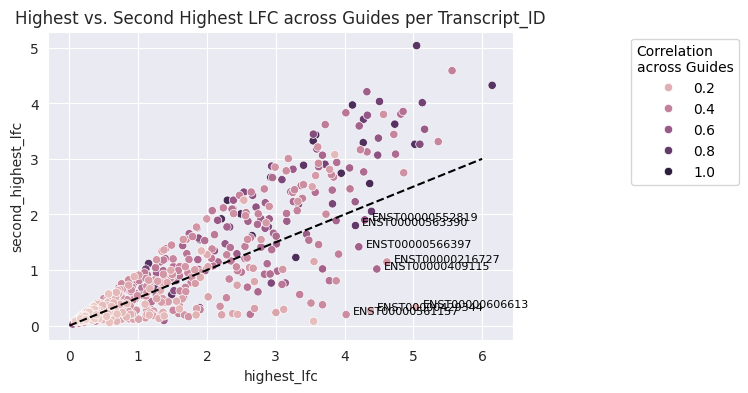

In [73]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6,4))
sns.scatterplot(data=guide_stats_df, x='highest_lfc', y='second_highest_lfc', hue='correlation', ax=ax)
pl.title(f'Highest vs. Second Highest LFC across Guides per {guide_groupby}')
pl.plot([0, 6], [0, 6 / 2], 'k--')
pl.legend(title='Correlation\nacross Guides')
mask = (guide_stats_df.highest_lfc>4) & (guide_stats_df.second_highest_lfc<2)
# annotate the outliers
for gene, row in guide_stats_df[mask].iterrows():
    ax.text(row.highest_lfc+0.1, row.second_highest_lfc, gene, fontsize=8)
sns.move_legend(ax, "upper right", bbox_to_anchor=(1.5, 1))
pl.show()

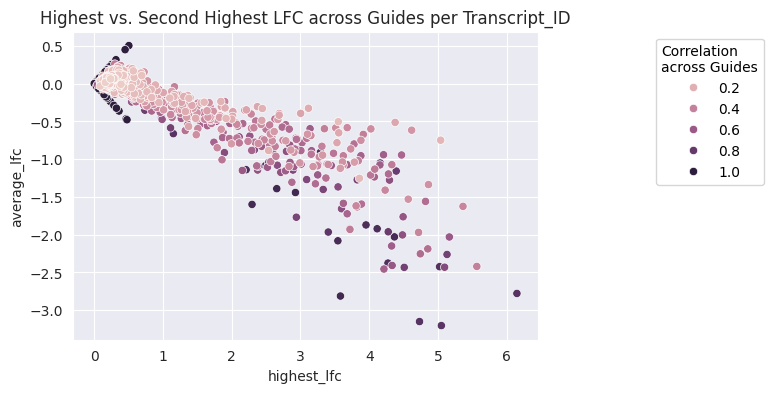

In [75]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6,4))
sns.scatterplot(data=guide_stats_df, x='highest_lfc', y='average_lfc', hue='correlation', ax=ax)
pl.title(f'Highest vs. Second Highest LFC across Guides per {guide_groupby}')
pl.legend(title='Correlation\nacross Guides')
mask = (guide_stats_df.highest_lfc>4) & (guide_stats_df.second_highest_lfc<2)
sns.move_legend(ax, "upper right", bbox_to_anchor=(1.5, 1))
pl.show()

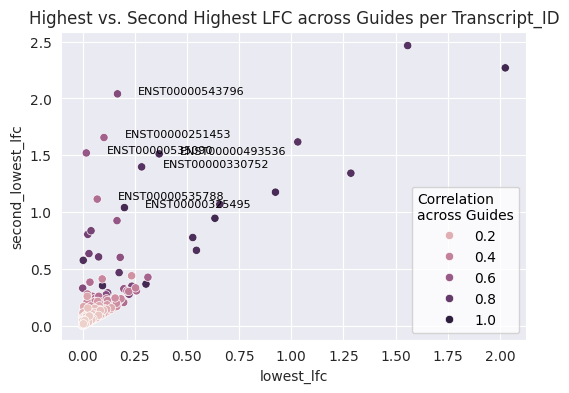

In [60]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6,4))
sns.scatterplot(data=guide_stats_df, x='lowest_lfc', y='second_lowest_lfc', hue='correlation', ax=ax)
pl.title(f'Highest vs. Second Highest LFC across Guides per {guide_groupby}')
pl.legend(title='Correlation\nacross Guides')
mask = (guide_stats_df.lowest_lfc<0.5) & (guide_stats_df.second_lowest_lfc>1)
# annotate the outliers
for gene, row in guide_stats_df[mask].iterrows():
    ax.text(row.lowest_lfc+0.1, row.second_lowest_lfc, gene, fontsize=8)

pl.show()

In [8]:
# some genes with potential single-guide outliers
guide_stats_df[mask]

,correlation,average_lfc,highest_lfc,second_highest_lfc,lowest_lfc,second_lowest_lfc
ENST00000325495,0.904155,-1.599481,2.295563,2.255703,0.200700,1.038533
ENST00000493536,0.900026,-2.029545,4.365579,2.556017,0.367248,1.511310
ENST00000330752,0.841750,-2.778945,6.145859,4.323246,0.283161,1.396774
ENST00000543796,0.682751,-2.431491,5.094721,3.263548,0.167461,2.039368
ENST00000535090,0.614723,-2.408398,4.332033,3.785553,0.018036,1.519630
ENST00000251453,0.558339,-2.455316,4.212908,3.592632,0.102725,1.655190
ENST00000535788,0.493394,-1.305908,2.874852,1.113261,0.070390,1.113261


In [9]:
df[df.Transcript_ID=='ENST00000563390']

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
RPS15A_ENST00000563390_324,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA302:302-324,TGCACGTCAAATCTGGGGCTGAT,324.0,0.980438,CDS,525.0,...,1569,1897,1389,1543,2101,1608,1554,1647,1219,1131
RPS15A_ENST00000563390_325,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA303:303-325,TTGCACGTCAAATCTGGGGCTGA,325.0,0.944003,CDS,525.0,...,795,840,693,638,1042,806,748,873,644,600
RPS15A_ENST00000563390_340,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA318:318-340,TTCCAGGTCTTTGAGTTGCACGT,340.0,0.993995,CDS,525.0,...,183,178,111,64,836,185,111,82,68,56
RPS15A_ENST00000563390_342,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA320:320-342,TTTTCCAGGTCTTTGAGTTGCAC,342.0,0.933769,CDS,525.0,...,1326,1559,1422,1503,1561,1339,1437,1715,1247,1498
RPS15A_ENST00000563390_424,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA383:402-424,TTCTTCATGGTCCATGATGCCAG,424.0,0.962256,CDS,525.0,...,701,754,713,574,1480,767,647,628,459,545
RPS15A_ENST00000563390_522,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA478:500-522,AGCACCAGAGTCCATGAGGCATT,522.0,0.952233,UTR3,525.0,...,1190,1205,959,816,1433,1293,1094,1111,799,859
RPS15A_ENST00000563390_523,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA479:501-523,AAGCACCAGAGTCCATGAGGCAT,523.0,0.990817,UTR3,525.0,...,1375,1483,1404,1375,1676,1245,1410,1677,1089,1259


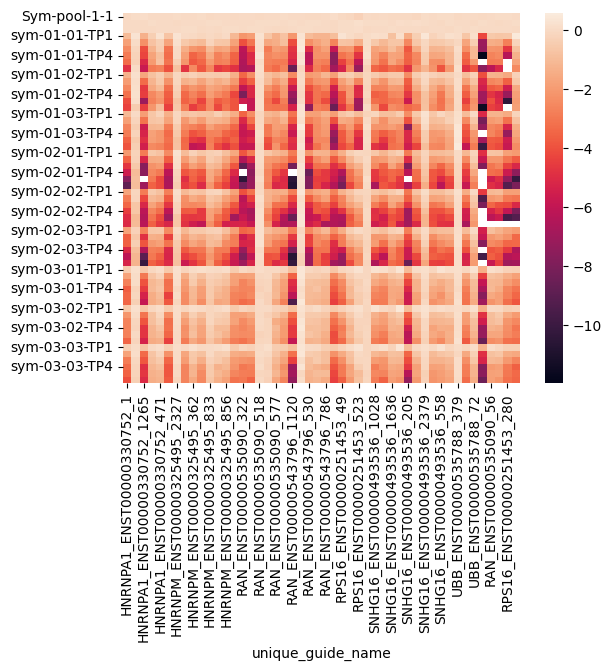

In [10]:
selection = guide_stats_df[mask].index
guides = df[df[guide_groupby].isin(selection)].index

data = l2fc.loc[guides].T

# annotate with pyComplexHeatmap
sns.heatmap(data)
pl.show()

<Axes: ylabel='unique_guide_name'>

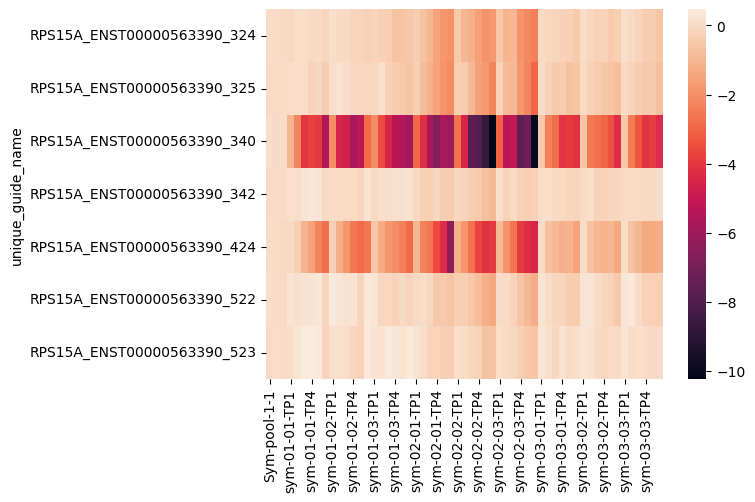

In [11]:
# great example for an outlier guide:
sns.heatmap(l2fc.loc[l2fc.index.str.contains('ENST00000563390'), :])

<Axes: ylabel='unique_guide_name'>

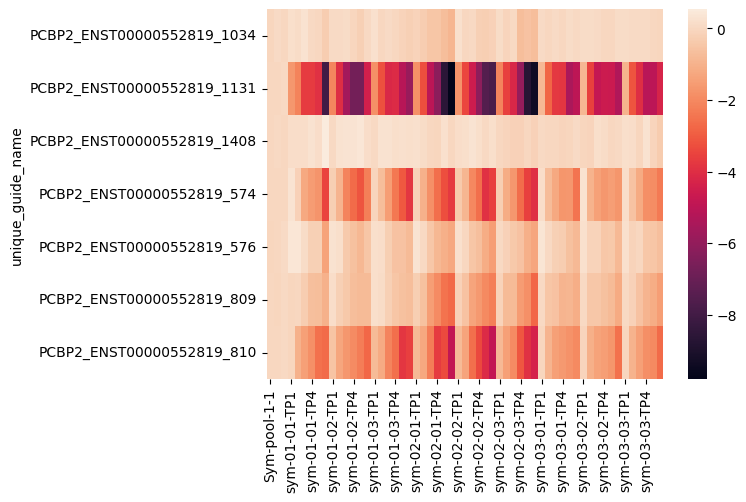

In [12]:
# great example for an outlier guide:
sns.heatmap(l2fc.loc[l2fc.index.str.contains('ENST00000552819'), :])

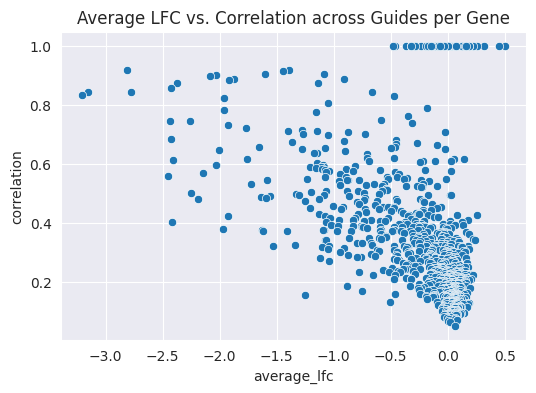

In [13]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6,4))
sns.scatterplot(data=guide_stats_df, x='average_lfc', y='correlation')
pl.title('Average LFC vs. Correlation across Guides per Gene')
pl.show()

In [14]:
# could I use deseq to analyse this? I don't think so, I am looking for outlier detection...

In [15]:
ldf

,Sym-pool-1-1,Sym-pool-1-2,Sym-pool-1-3,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,sym-01-01-TP6,sym-01-02-TP1,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
ZSWIM3_ENST00000255152_1242,0.009880,-0.015187,0.005184,0.364638,0.417351,0.359797,0.274820,0.252852,-0.243349,0.085702,...,0.199894,0.063253,0.368487,0.314602,0.101795,0.165369,0.208941,0.047973,0.157361,0.040312
ZSWIM3_ENST00000255152_1357,-0.038404,-0.000676,0.038067,0.105199,0.203624,0.303042,0.331314,0.284673,-0.107285,-0.166488,...,0.126607,0.034478,0.003867,0.139065,0.031873,-0.020502,-0.119035,0.119387,-0.121404,-0.200486
ZSWIM3_ENST00000255152_164,-0.059158,0.029032,0.028354,0.323026,0.279262,0.522056,0.439393,0.499221,0.275495,-0.008400,...,0.208654,0.181810,0.197862,0.170973,0.190069,0.243116,0.244725,0.218544,0.202481,0.269581
ZSWIM3_ENST00000255152_2431,-0.023360,0.005627,0.017428,0.203692,-0.012461,-0.005766,-0.005312,-0.128262,0.195416,0.019722,...,0.126035,0.209303,0.234824,0.206383,0.057351,-0.027740,0.083453,0.166186,-0.048886,0.014664
ZSWIM3_ENST00000255152_2528,0.003825,-0.015637,0.011675,0.192674,0.307431,0.334450,0.441067,0.465153,0.011080,-0.061146,...,0.089903,-0.035914,-0.052731,-0.072836,0.161837,0.149989,0.096834,0.088599,-0.125292,-0.158753
ZSWIM3_ENST00000255152_32,0.013393,-0.034953,0.020926,-0.056449,0.208550,0.074120,-0.047415,0.042594,-0.502944,-0.172458,...,-0.031528,-0.093006,0.128799,0.003348,0.092109,-0.047353,-0.244074,-0.146657,-0.091725,-0.132397
ZSWIM3_ENST00000255152_665,-0.085300,0.061587,0.019770,0.134589,0.271410,0.072880,0.064636,0.321402,-0.024407,-0.033636,...,-0.034514,-0.009597,0.072734,0.037480,0.166235,0.154062,-0.028170,0.032647,-0.057593,0.026877


# Region Specificity

In [77]:
L = l2fc.copy()
L['Region'] = df.Region.copy()
L['Gene'] = df.Gene.copy()
# Ignore "Gene_Body" for now. It's mututally exclusive with "CDS" and "5'UTR" and "3'UTR"

mean_l2fc_per_gene_and_region = L.groupby(['Gene', 'Region']).mean().mean(axis=1).unstack()

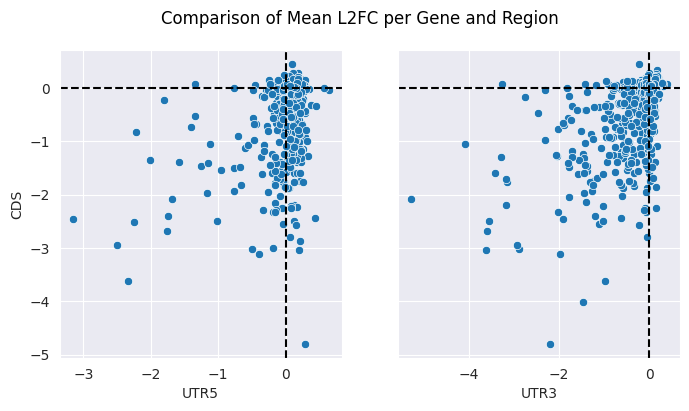

In [78]:
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(4*2,4), sharey=True)
for ax, key in zip(axs, ['UTR5', 'UTR3']):
    sns.scatterplot(data=mean_l2fc_per_gene_and_region, y='CDS', x=key, ax=ax)
    ax.axhline(0, color='k', linestyle='--')
    ax.axvline(0, color='k', linestyle='--')
pl.suptitle('Comparison of Mean L2FC per Gene and Region')
pl.show()

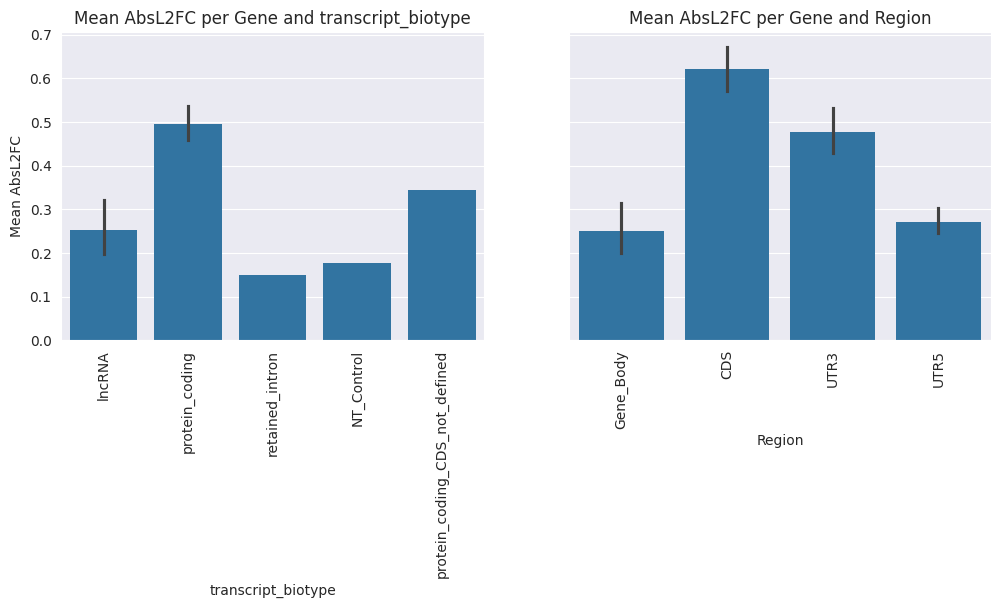

In [79]:
keys = ['transcript_biotype', 'Region']
N = len(keys)

with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, N, figsize=(6*N,4), sharey=True)

for key, ax in zip(keys, axs):
    L = np.abs(l2fc.copy())
    L['Gene'] = df.Gene.copy()
    L[key] = df[key].copy()
    data = L.groupby(['Gene', key]).mean().mean(axis=1).reset_index()
    sns.barplot(data=data, x=key, y=0, ax=ax)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    ax.set_ylabel('Mean AbsL2FC')
    ax.set_title(f'Mean AbsL2FC per Gene and {key}')
pl.show()


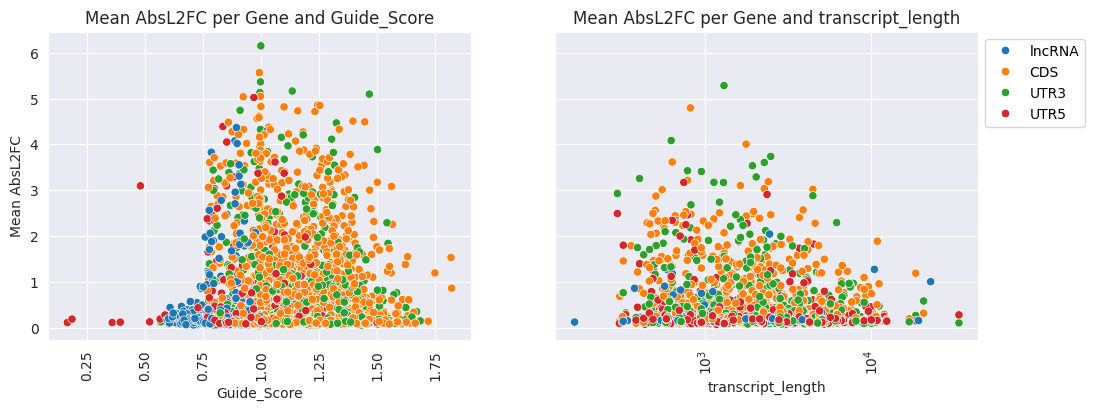

In [80]:
keys = ['Guide_Score', 'transcript_length']
N = len(keys)
hue = 'Region'

with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, N, figsize=(6*N,4), sharey=True)

for key, ax in zip(keys, axs):
    L = np.abs(l2fc.copy())
    L['Gene'] = df.Gene.copy()
    L[key] = df[key].copy()
    L[hue] = df[hue].copy()
    if hue == 'Region':
        L[hue] = L[hue].replace({'Gene_Body': 'lncRNA'})
    data = L.groupby(['Gene', hue, key]).mean().mean(axis=1).reset_index()
    sns.scatterplot(data=data, x=key, y=0, ax=ax, hue=hue)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    ax.set_ylabel('Mean AbsL2FC')
    ax.set_title(f'Mean AbsL2FC per Gene and {key}')
    if key=='transcript_length':
        ax.set_xscale('log')
    if ax==axs[1]:
        ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    else:
        ax.get_legend().remove()
pl.show()


In [81]:
df.transcript_biotype

unique_guide_name
AATBC_ENST00000400385_1005            lncRNA
AATBC_ENST00000400385_1562            lncRNA
AATBC_ENST00000400385_1938            lncRNA
AATBC_ENST00000400385_2713            lncRNA
AATBC_ENST00000400385_28              lncRNA
                                   ...      
RPS16_ENST00000251453_280     protein_coding
RPS16_ENST00000251453_300     protein_coding
RPS5_ENST00000196551_431      protein_coding
RPS5_ENST00000196551_574      protein_coding
RPS5_ENST00000196551_68       protein_coding
Name: transcript_biotype, Length: 6225, dtype: object

# Differential transcript depletion

In [196]:
# Find genes where transcripts showed different reactions
# Can't use BAGEL for this. Will work on L2FC instead.
# Restrict to protein-coding region
sdf = df[df.Region=='CDS'].copy()
multi_transcript_genes = [gene for gene in sdf.Gene.unique() if len(sdf[sdf.Gene == gene].Transcript_ID.unique()) > 1]

In [214]:
sdf = sdf[sdf.Gene.isin(multi_transcript_genes)]
L = l2fc.loc[sdf.index, sample_names_wo_pools]

In [215]:
L

,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,sym-01-01-TP6,sym-01-02-TP1,sym-01-02-TP2,sym-01-02-TP3,sym-01-02-TP4,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
ANAPC11_ENST00000344877_202,0.412015,0.369900,0.536509,0.580091,0.308489,-0.108070,0.242893,0.290519,0.045819,-0.035401,...,0.212249,0.095490,0.172924,0.037166,0.216169,0.261061,0.158150,0.190354,-0.155788,-0.109976
ANAPC11_ENST00000344877_204,0.474597,0.362447,0.335433,0.136449,0.027478,0.301345,0.364665,0.317609,0.363202,0.278205,...,0.075000,-0.045905,-0.075150,0.044423,0.294426,0.167683,0.261667,-0.012816,0.102772,0.103529
ANAPC11_ENST00000344877_374,0.201372,-0.037688,-0.050779,-0.031956,0.060283,0.085101,0.001154,-0.054299,0.034638,0.098147,...,0.147123,0.036241,-0.043348,0.008732,0.101639,0.153108,0.074120,0.077000,-0.100733,0.062741
ANAPC11_ENST00000579978_232,0.214941,-0.150430,0.076992,0.081761,0.185460,-0.138536,-0.194746,-0.123923,-0.226552,-0.254744,...,-0.045684,-0.226075,-0.273500,-0.228488,-0.013864,-0.029551,-0.081301,-0.256966,-0.244536,-0.255292
ANAPC11_ENST00000579978_233,-0.110474,0.181127,0.244365,0.283041,0.177209,0.147443,0.198662,0.169761,0.305489,0.171650,...,-0.006661,0.101077,0.130046,0.035998,-0.077720,-0.000240,-0.115191,0.107115,-0.064436,-0.200174
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2_ENST00000370920_541,0.233212,-0.014063,-0.894476,-1.445218,-1.808668,-2.502527,0.023167,-0.303353,-1.184761,-1.396507,...,-0.378122,-0.424553,-0.225600,-0.405982,0.172480,-0.206880,-0.214627,-0.429636,-0.404641,-0.540435
ZRANB2_ENST00000370920_738,0.108466,0.161241,0.244252,0.268561,0.125397,-0.177507,0.038689,-0.058115,-0.092975,-0.090920,...,-0.086082,-0.071181,-0.067710,-0.072547,0.072926,-0.067302,0.248733,-0.070964,-0.018676,0.085130
FBL_ENST00000597224_524,-0.613396,-2.965704,-6.943970,NaN,NaN,-9.709505,-1.496899,-3.964667,-7.497011,-6.704697,...,-2.179622,-2.726729,-2.476917,-2.966255,-0.037557,-1.469564,-2.157222,-3.057713,-3.221471,-3.252916


In [256]:
L['Gene'] = sdf.Gene.copy()
L['Transcript_ID'] = sdf.Transcript_ID.copy()
mL = data.groupby(['Gene', 'Transcript_ID']).mean()
mmL = mL.mean(axis=1).to_frame().sort_values(0, ascending=False)
# annotate the Transcript_ID number of each gene
mmL['Transcript_ID_number'] = mmL.groupby('Gene').cumcount()+1
mmL.set_index('Transcript_ID_number', append=True, inplace=True)
mmL = mmL.reset_index()

In [257]:
mmL

,Gene,Transcript_ID,Transcript_ID_number,0
0,MBD1,ENST00000347968,1,0.340078
1,PCBP4,ENST00000355852,1,0.309204
2,STARD8,ENST00000374597,1,0.253109
3,ATP5F1D,ENST00000215375,1,0.234240
4,PCBP4,ENST00000471622,2,0.218523
...,...,...,...,...
176,PPIA,ENST00000355968,2,-2.614012
177,UBE2I,ENST00000403747,2,-2.647368
178,RNPS1,ENST00000320225,2,-2.655010
179,NUTF2,ENST00000569436,2,-3.367088


In [258]:
# now make a scatterplot where x is number 1 and y is number 2
# first need to pivot the table
pmmL = mmL.pivot(index='Gene', columns='Transcript_ID_number', values=0)

pmmL['min_l2fc'] = pmmL.min(axis=1, skipna=True)
pmmL['max_l2fc'] = pmmL.max(axis=1, skipna=True)

In [259]:
pmmL

Transcript_ID_number,1,2,3,4,min_l2fc,max_l2fc
Gene,,,,,,
ANAPC11,-0.096340,-0.124690,NaN,NaN,-0.124690,-0.096340
ANAPC5,-0.538551,-1.244899,NaN,NaN,-1.244899,-0.538551
ATP5F1D,0.234240,-0.057472,NaN,NaN,-0.057472,0.234240
ATRAID,0.091821,0.009516,NaN,NaN,0.009516,0.091821
ATXN7L3,-0.031660,-0.077083,NaN,NaN,-0.077083,-0.031660
...,...,...,...,...,...,...
VARS2,-0.062155,-0.107240,NaN,NaN,-0.107240,-0.062155
WWP1,-0.186620,-0.859499,NaN,NaN,-0.859499,-0.186620
ZFAND6,0.140269,0.128588,-0.005544,NaN,-0.005544,0.140269


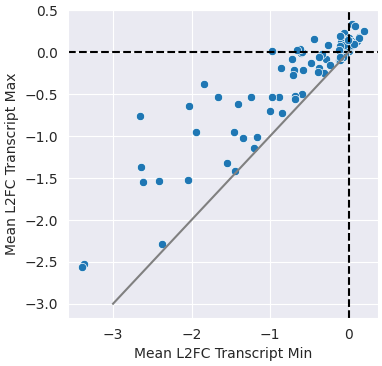

In [268]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(4,4))
sns.scatterplot(data=pmmL, x='min_l2fc', y='max_l2fc', ax=ax)
pl.xlabel('Mean L2FC Transcript Min')
pl.ylabel('Mean L2FC Transcript Max')
pl.axhline(0, color='k', linestyle='--')
pl.axvline(0, color='k', linestyle='--')
# draw diagonal
pl.plot([-3, 0], [-3, 0], 'grey')
pl.show()

In [280]:
hits = (pmmL.max_l2fc - pmmL.min_l2fc).sort_values(ascending=False).index[:10]
dat = mL.loc[hits]

<Axes: ylabel='Gene-Transcript_ID'>

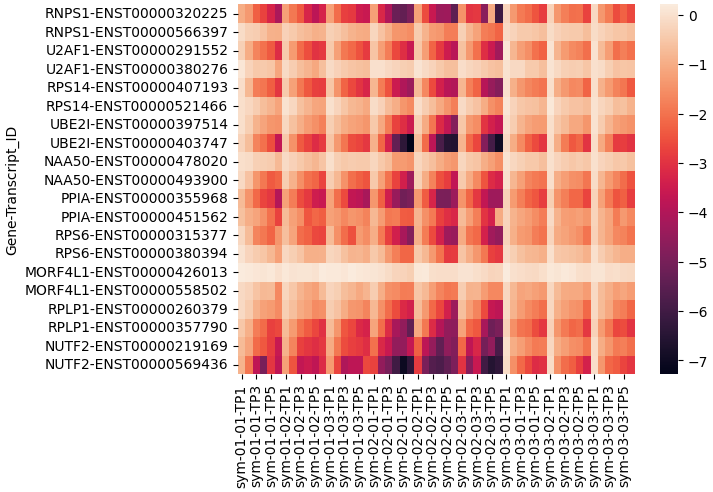

In [281]:
sns.heatmap(dat)

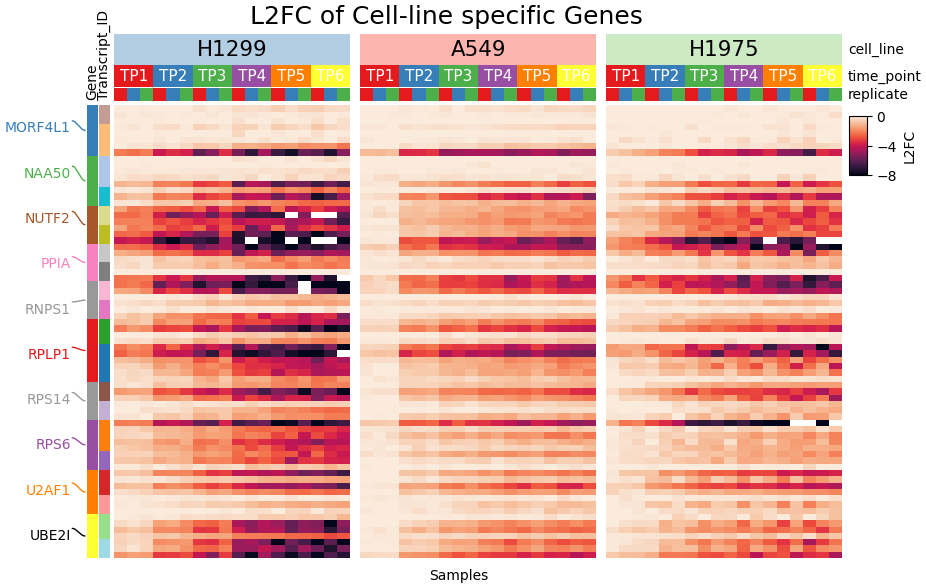

In [289]:
# correlation between samples
cell_line = pd.Series({x: int(x.split('-')[1]) for x in sample_names_wo_pools}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names_wo_pools})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names_wo_pools})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

data = l2fc.loc[df.Gene.isin(hits) & (df.Region == 'CDS'), col_order].sort_index()

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=5, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df.loc[data.index, 'Gene'], merge=True, extend=True),
    Gene=pch.anno_simple(df.loc[data.index, 'Gene']),
    Transcript_ID=pch.anno_simple(df.loc[data.index, 'Transcript_ID']),
    verbose=0, axis=0, plot_legend=False
)

pl.figure(figsize=(10, 6))
cm = pch.ClusterMapPlotter(
    data=data, top_annotation=top_ha, left_annotation=left_ha,
    row_cluster=False, col_cluster=False,
    legend_gap=7, vmax=0, vmin=-8,
    col_split=cell_line.loc[col_order], col_split_gap=2.5,
    rasterized=True, cmap='rocket',
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='', legend_hpad=0,
    verbose=0
)
pl.suptitle("L2FC of Cell-line specific Genes", y=0.93, fontsize=18)
pl.show()

# Differences between cell lines / samples

In [83]:
import PyComplexHeatmap as pch

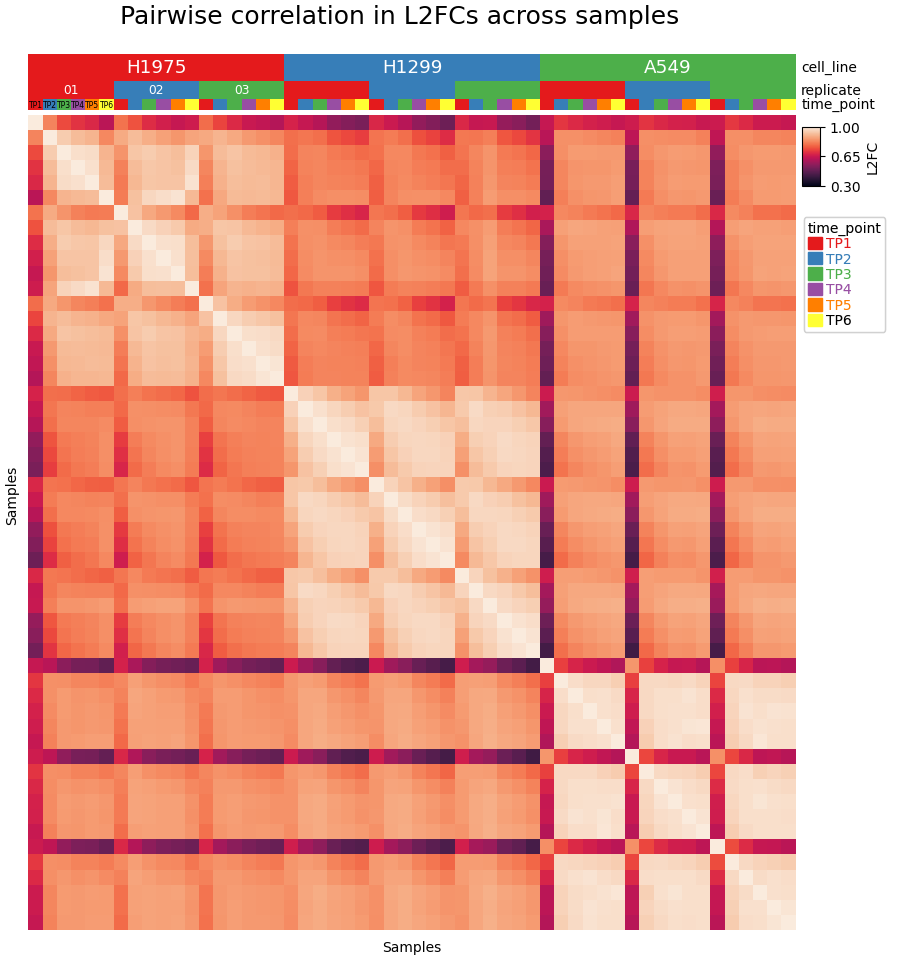

In [84]:
# correlation between samples
data = l2fc.loc[:, sample_names_wo_pools].corr()

cell_line = pd.Series({x: int(x.split('-')[1]) for x in data.columns}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2] for x in data.columns})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in data.columns})

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line, add_text=True, height=6, legend=False),
    replicate=pch.anno_simple(replicate, add_text=True, height=4, legend=False),
    time_point=pch.anno_simple(time_point, add_text=True, height=2.5, text_kws={'color': 'black'}),
    verbose=0, axis=1, plot_legend=True
)

pl.figure(figsize=(10, 10))
cm = pch.ClusterMapPlotter(
    data=data, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    legend_gap=7, vmin=0.3,
    rasterized=True, cmap='rocket',
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Samples', legend_hpad=0,
    verbose=0
)
pl.suptitle("Pairwise correlation in L2FCs across samples", y=0.93, fontsize=18)
pl.show()

In [126]:
# Use results from BAGEL2 to detect cell line specific essential genes
bagel = pd.read_table('../results/tables/pooled_screen_1_bagel_pr_gene.tsv', index_col=0, header=[0,1,2])
sdf = bagel.xs('BF', level=2, axis=1).xs('alltimes', level=1, axis=1)

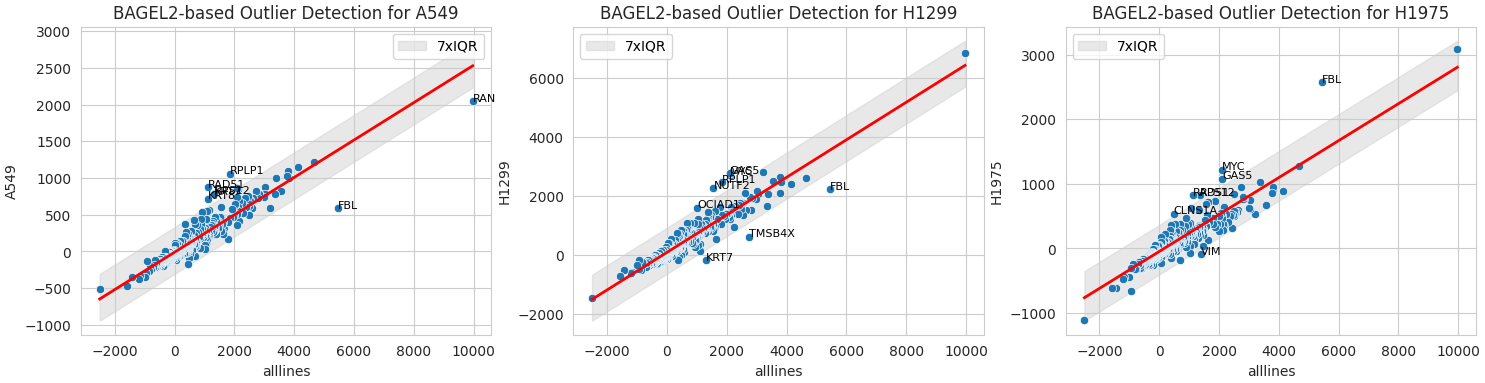

In [140]:
from sklearn import linear_model

outlier_genes_up = {}
outlier_genes_down = {}
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 3, figsize=(6 * 3,4))

for ax, line in zip(axs, ['A549', 'H1299', 'H1975']):
    xkey = 'alllines'
    ykey = line

    # Data #
    x, y = sdf[xkey].values.reshape(-1, 1), sdf[ykey].values.reshape(-1, 1)
    # Make fit #
    regr = linear_model.LinearRegression()
    regr.fit(x, y)
    y_pred = regr.predict(x)

    # Detect outliers #
    residuals = y - y_pred
    IQR = np.percentile(residuals, 75) - np.percentile(residuals, 25)
    Q1 = np.percentile(residuals, 25)
    Q3 = np.percentile(residuals, 75)
    factor = 7 # width of the IQR zone for outlier detection
    mask_up = np.ravel(((residuals > Q3 + factor*IQR)) & (y_pred > 0))
    mask_down = np.ravel(((residuals < Q1 - factor*IQR)) & (y_pred > 0))
    mask = mask_up | mask_down
    outlier_genes_up[line] = sdf.index[mask_up].tolist()
    outlier_genes_down[line] = sdf.index[mask_down].tolist()

    # Plot #
    sns.scatterplot(data=sdf, x=xkey, y=ykey, ax=ax)
    ax.plot(x, y_pred, color='red', linewidth=2)
    for i, txt in enumerate(sdf.index[mask]):
        ax.annotate(txt, (x[mask][i], y[mask][i]), fontsize=8)
    ax.fill_between(np.ravel(x), np.ravel(y_pred - Q1 - factor*IQR), np.ravel(y_pred + Q3 + factor*IQR), 
                    color='lightgray', alpha=0.5, zorder=-1, label=f'{factor}xIQR')
    ax.set_title(f'BAGEL2-based Outlier Detection for {line}')
    ax.legend()
pl.show()

In [145]:
# this is a dict of lists of genes that are outliers in the respective cell lines
# make it a dataframe where index is gene and columns are cell lines
index = list(set(outlier_genes_up['A549'] + outlier_genes_up['H1299'] + outlier_genes_up['H1975'] + \
                 outlier_genes_down['A549'] + outlier_genes_down['H1299'] + outlier_genes_down['H1975']
                 ))
outlier_df = pd.DataFrame(0, index=index, columns=['A549', 'H1299', 'H1975'])
for line in ['A549', 'H1299', 'H1975']:
    outlier_df.loc[outlier_genes_up[line], line] = 1
    outlier_df.loc[outlier_genes_down[line], line] = -1
# outlier_df is per gene; make per guide
# is_outlier_guide = pd.DataFrame({guide: outlier_df.loc[gene] for guide, gene in zip(df.index, df.Gene) if gene in outlier_df.index}).T.astype(str)
is_outlier_guide = pd.DataFrame({guide: outlier_df.loc[gene] for guide, gene in zip(df.index, df.Gene) if gene in outlier_df.index}).T

In [146]:
is_outlier_guide

,A549,H1299,H1975
CLNS1A_ENST00000263309_1047,0,0,1
CLNS1A_ENST00000263309_1075,0,0,1
CLNS1A_ENST00000263309_127,0,0,1
CLNS1A_ENST00000263309_260,0,0,1
CLNS1A_ENST00000263309_302,0,0,1
...,...,...,...
FBL_ENST00000597224_524,-1,-1,1
NUTF2_ENST00000219169_389,0,1,0
NUTF2_ENST00000569436_682,0,1,0
RAN_ENST00000535090_56,-1,0,0


In [132]:
outlier_genes

{'A549': ['RAN', 'FBL', 'RPLP1', 'RPS12', 'KRT7', 'RAD51', 'KRT8'],
 'H1299': ['FBL', 'TMSB4X', 'MYC', 'GAS5', 'RPLP1', 'NUTF2', 'KRT7', 'OCIAD1'],
 'H1975': ['FBL', 'MYC', 'GAS5', 'VIM', 'RPS12', 'RAD51', 'CLNS1A']}

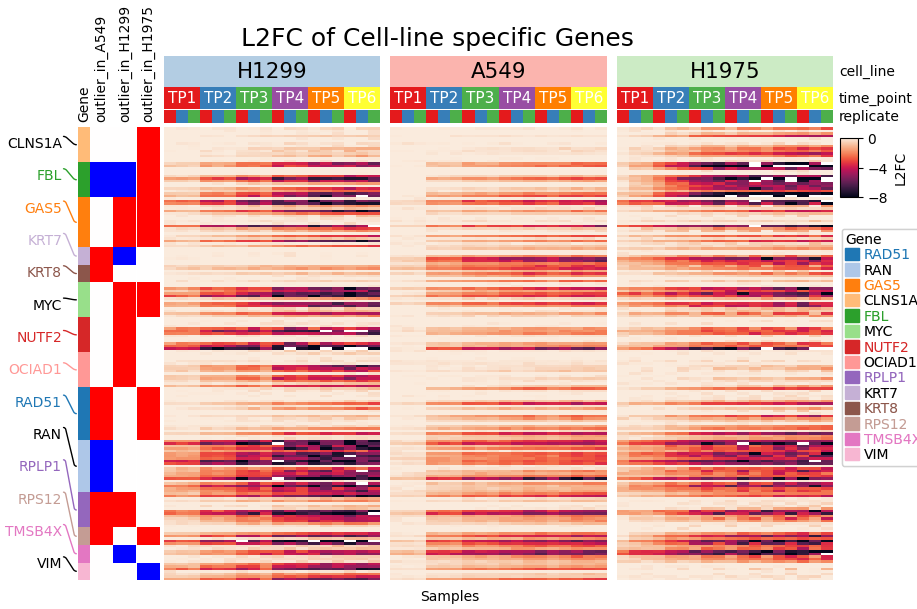

In [150]:
# correlation between samples
data = l2fc.loc[df.Gene.isin(index), sample_names_wo_pools].sort_index()

cell_line = pd.Series({x: int(x.split('-')[1]) for x in data.columns}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2] for x in data.columns})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in data.columns})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

data = data.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=5, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

kwargs = dict(height=6, cmap='bwr', legend=False)
left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df.loc[data.index, 'Gene'], merge=True, extend=True),
    Gene=pch.anno_simple(df.loc[data.index, 'Gene']),
    outlier_in_A549=pch.anno_simple(is_outlier_guide['A549'], **kwargs),
    outlier_in_H1299=pch.anno_simple(is_outlier_guide['H1299'], **kwargs),
    outlier_in_H1975=pch.anno_simple(is_outlier_guide['H1975'], **kwargs),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(10, 6))
cm = pch.ClusterMapPlotter(
    data=data, top_annotation=top_ha, left_annotation=left_ha,
    row_cluster=False, col_cluster=False,
    legend_gap=7, vmax=0, vmin=-8,
    col_split=cell_line.loc[col_order], col_split_gap=2.5,
    rasterized=True, cmap='rocket',
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='', legend_hpad=0,
    verbose=0
)
pl.suptitle("L2FC of Cell-line specific Genes", y=0.93, fontsize=18)
pl.show()